In [1]:

import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1]
])

Y_OR = np.array([0, 1, 1, 1])
Y_AND = np.array([0, 0, 0, 1])

print("X1  X2  OR  AND")
print("----------------")
for i in range(len(X)):
    print(X[i, 0], " ", X[i, 1], " ", Y_OR[i], "   ", Y_AND[i])


X1  X2  OR  AND
----------------
0   0   0     0
1   0   1     0
0   1   1     0
1   1   1     1


In [2]:

def activation(z):
    return 1 if z >= 0 else 0

def perceptron(x, poids, biais):
    z = np.dot(x, poids) + biais
    return activation(z)

poids_or = np.array([1, 1])
biais_or = -0.5

poids_and = np.array([1, 1])
biais_and = -1.5

print("X1  X2  OR  AND")
print("----------------")

for x in X:
    y_or = perceptron(x, poids_or, biais_or)
    y_and = perceptron(x, poids_and, biais_and)

    print(f"{x[0]}   {x[1]}   {y_or}    {y_and}")


X1  X2  OR  AND
----------------
0   0   0    0
1   0   1    0
0   1   1    0
1   1   1    1


In [3]:

from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

Y_XOR = np.array([0, 1, 1, 0])

modele_xor = Perceptron(
    max_iter=1000,
    tol=1e-4,
    random_state=42
)

modele_xor.fit(X, Y_XOR)


Y_pred = modele_xor.predict(X)

print("X1  X2  XOR attendu  XOR prédit")
print("--------------------------------")

for i in range(len(X)):
    print(f"{X[i,0]}   {X[i,1]}       {Y_XOR[i]}           {Y_pred[i]}")

accuracy = accuracy_score(Y_XOR, Y_pred)

print("\nAccuracy :", accuracy * 100, "%")
print("Poids :", modele_xor.coef_)
print("Biais :", modele_xor.intercept_)


X1  X2  XOR attendu  XOR prédit
--------------------------------
0   0       0           0
1   0       1           0
0   1       1           0
1   1       0           0

Accuracy : 50.0 %
Poids : [[0. 0.]]
Biais : [0.]


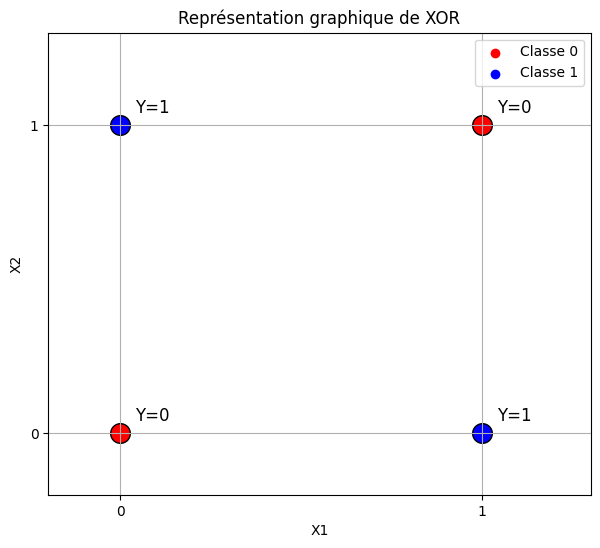

In [4]:

import matplotlib.pyplot as plt
import numpy as np

X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1]
])

Y_XOR = np.array([0, 1, 1, 0])

plt.figure(figsize=(7, 6))

for i in range(len(X)):
    if Y_XOR[i] == 0:
        plt.scatter(X[i, 0], X[i, 1],
                    color="red", s=200,
                    edgecolors="black")
    else:
        plt.scatter(X[i, 0], X[i, 1],
                    color="blue", s=200,
                    edgecolors="black")

    plt.text(X[i, 0] + 0.04,
             X[i, 1] + 0.04,
             f"Y={Y_XOR[i]}", fontsize=12)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Représentation graphique de XOR")

plt.xticks([0, 1])
plt.yticks([0, 1])
plt.xlim(-0.2, 1.3)
plt.ylim(-0.2, 1.3)
plt.grid(True)

plt.scatter([], [], color="red", label="Classe 0")
plt.scatter([], [], color="blue", label="Classe 1")
plt.legend()

plt.show()


In [5]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import numpy as np

X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1]
])

Y_XOR = np.array([0, 1, 1, 0])

mlp_xor = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation="tanh",
    solver="lbfgs",
    max_iter=5000,
    random_state=42
)

mlp_xor.fit(X, Y_XOR)


Y_pred_mlp = mlp_xor.predict(X)

accuracy_mlp = accuracy_score(Y_XOR, Y_pred_mlp)

print("X1  X2  XOR attendu  XOR prédit")
print("--------------------------------")

for i in range(len(X)):
    print(f"{X[i,0]}   {X[i,1]}       {Y_XOR[i]}           {Y_pred_mlp[i]}")

print("\nAccuracy MLP :", accuracy_mlp * 100, "%")

print("\nArchitecture du réseau :")
print("Entrées :", X.shape[1])
print("Neurones cachés :", mlp_xor.hidden_layer_sizes)
print("Sortie : 1 neurone")


X1  X2  XOR attendu  XOR prédit
--------------------------------
0   0       0           0
1   0       1           1
0   1       1           1
1   1       0           0

Accuracy MLP : 100.0 %

Architecture du réseau :
Entrées : 2
Neurones cachés : (4,)
Sortie : 1 neurone


Application sur Données Réelles – Iris (3 types de
fleurs)

In [6]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

iris = load_iris()

X_iris = iris.data
y_iris = iris.target

df = pd.DataFrame(
    X_iris,
    columns=iris.feature_names
)

df["Espèce"] = y_iris

print("Les 5 premières lignes du dataset :")
display(df.head())

print("\nNombre d'échantillons :", X_iris.shape[0])
print("Nombre de caractéristiques :", X_iris.shape[1])
print("Classes :", iris.target_names)

X_train, X_test, y_train, y_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

print("\nDonnées d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)


Les 5 premières lignes du dataset :


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Espèce
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Nombre d'échantillons : 150
Nombre de caractéristiques : 4
Classes : ['setosa' 'versicolor' 'virginica']

Données d'entraînement : (120, 4)
Données de test : (30, 4)


In [7]:

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

mlp_iris = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)

mlp_iris.fit(X_train_scaled, y_train)

y_pred_iris = mlp_iris.predict(X_test_scaled)

accuracy_iris = accuracy_score(y_test, y_pred_iris)

print("===== RÉSULTATS DU MLP IRIS =====")
print("Architecture : 4 - 10 - 3")
print("Nombre d'itérations :", mlp_iris.n_iter_)
print("Accuracy :", round(accuracy_iris * 100, 2), "%")

print("\nClasses réelles :", y_test)
print("Classes prédites :", y_pred_iris)


===== RÉSULTATS DU MLP IRIS =====
Architecture : 4 - 10 - 3
Nombre d'itérations : 948
Accuracy : 96.67 %

Classes réelles : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Classes prédites : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


===== MATRICE DE CONFUSION =====
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

===== RAPPORT DE CLASSIFICATION =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Accuracy globale : 96.67 %


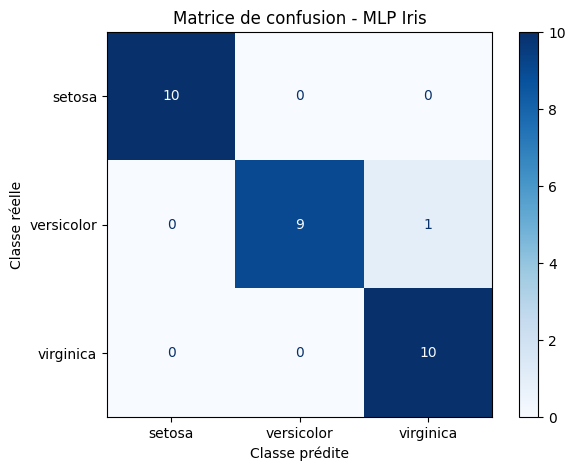

In [8]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_iris)

print("===== MATRICE DE CONFUSION =====")
print(cm)

print("\n===== RAPPORT DE CLASSIFICATION =====")
print(classification_report(
    y_test,
    y_pred_iris,
    target_names=iris.target_names
))

print("Accuracy globale :",
      round(accuracy_score(y_test, y_pred_iris)*100, 2), "%")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Matrice de confusion - MLP Iris")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()
